# Ind GP vs Vanilla BO — network_2corridor

In [5]:
import os
import sys
import json
import shutil
import pprint
import time
from pathlib import Path

# Add project root first so "src" and "helpers_od_calibration_BN" can be imported
base_path = Path.cwd()
if base_path.name == "notebook_for_toy":
    base_path = base_path.parent
elif not (base_path / "src").exists():
    base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
if str(base_path) not in sys.path:
    sys.path.insert(0, str(base_path))
os.chdir(base_path)

os.environ['SUMO_HOME'] = '/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo'
os.environ['LIBSUMO_AS_TRACI'] = '1'
SUMO_HOME = Path(os.environ['SUMO_HOME'])

if "SUMO_HOME" in os.environ:
    tools = os.path.join(os.environ["SUMO_HOME"], "tools")
    sys.path.append(tools)
else:
    sys.exit("Please declare the environment variable 'SUMO_HOME'")

SUMO_ROOT = Path(os.environ["SUMO_HOME"]).parents[1]
SUMO_BIN = str(SUMO_ROOT / "bin")
LIB_SUMO_PATH = Path(os.environ["SUMO_HOME"]).parents[2] / "lib" / "libsumo.dylib"
os.environ["PATH"] = SUMO_BIN + os.pathsep + os.environ.get("PATH", "")

import traci
import sumolib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats
from torch.quasirandom import SobolEngine

from botorch.acquisition import ExpectedImprovement, qLogExpectedImprovement
from botorch.exceptions import ModelFittingError
from botorch.fit import fit_gpytorch_mll
from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.optim import optimize_acqf
from botorch.sampling.stochastic_samplers import StochasticSampler
from botorch.utils.transforms import normalize, unnormalize
from gpytorch.constraints import Interval
from gpytorch.kernels import MaternKernel, ScaleKernel
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.settings import max_cholesky_size
from gpytorch.utils.errors import NotPSDError

from src.models.gp_models import (
    initialize_independent_gp_models_with_modellist,
    make_linear_aggregation_model_from_error_gps,
    extract_independent_gp_hyperparameters,
    initialize_vanillabo_model,
)
from src.utils.seed import set_seed
from src.simulation.sumo_runner import (
    create_od_xml,
    create_taz_xml,
    simulate_od,
    parse_loop_data_xml_to_pandas,
)
from src.optimization.bo_loop import BayesianOptimizationLoop
from src.optimization.restarts import run_multiple_bo_restarts

from helpers_od_calibration_BN import load_kwargs_config
from src.simulation.data_loader import od_xml_to_df
from src.utils.link_flow_analysis import (
    compute_squared_metric_all_edge as compute_squared_metric_all_edge,
    compute_squared_metric_per_edge as compute_squared_metric_per_edge,
    compute_cubic_metric_per_edge as compute_cubic_metric_per_edge,
)

%matplotlib inline

config = load_kwargs_config(base_path, "bo_vanilla", sim_setup_filename="sim_setup_network_2corridor.json")
Path(config["simulation_run_path"]).mkdir(parents=True, exist_ok=True)
pprint.pprint(dict(config))

{'BATCH_SIZE': 1,
 'BO_batch_size': 1,
 'BO_niter': 20,
 'BO_num_restarts': 1,
 'BO_raw_samples': 256,
 'BO_sample_shape': 64,
 'CLEANUP_INTERMEDIATE_FILES': False,
 'EARLY_STOP_DELTA': 1e-06,
 'EARLY_STOP_MIN_ACQ': 0.0,
 'EARLY_STOP_PATIENCE': 0,
 'EDGE_OUT_STR': 'edge_data.xml',
 'NITER': 20,
 'NUM_RESTARTS': 1,
 'RAW_SAMPLES': 256,
 'SAMPLE_SHAPE': 64,
 'SUMO_PATH': PosixPath('/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo'),
 'TRIPS2ODS_OUT_STR': 'trips.xml',
 'additional_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/additional.xml'),
 'file_gt_od': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/od.xml'),
 'fixed_routes': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/routes_single.csv'),
 'kernel': 'matern-2p5',
 'model_name': 'bo_vanilla',
 'n_init_search': 20,
 'net_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od

# GT data

In [6]:
# Get Ground Truth OD + fixed routes
print(f"Reading: {config['file_gt_od']}")
gt_od_df = od_xml_to_df(config["file_gt_od"])

print(f"Reading: {config['fixed_routes']}")
routes_df = pd.read_csv(config["fixed_routes"], index_col=0)

Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/od.xml
Total GT demand: 23261.0
Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/routes_single.csv


In [7]:
# gt od vector

simulation_gt_run_path =f'{config["simulation_run_path"]}/ground_truth'
prefix_output_gt = f'{simulation_gt_run_path}/sim'
sim_edge_out_gt = f'{prefix_output_gt}_{config["EDGE_OUT_STR"]}'
new_od_xml = f'{simulation_gt_run_path}/od.xml'

Path(simulation_gt_run_path).mkdir(parents=True, exist_ok=True)

base_od = gt_od_df.copy()
gt_od_vals = gt_od_df['count'].astype(float).to_numpy()
curr_od = gt_od_vals.copy()
base_od['count'] = curr_od
base_od = base_od.rename(columns={'fromTaz':'from', 'toTaz':'to'})
create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

print(base_od)


# Run simulation
simulate_od(new_od_xml,
            prefix_output_gt,
            base_path,
            config["net_xml"],
            config["taz2edge_xml"],
            config["additional_xml"],
            routes_df,
            config["sim_end_time"],
            config["TRIPS2ODS_OUT_STR"])

Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/ground_truth/od.xml
      from      to   count
0    taz_0   taz_1   148.0
1    taz_0  taz_60   440.0
2    taz_0  taz_61   923.0
3    taz_0  taz_62  1489.0
4    taz_0  taz_63  1620.0
5    taz_0  taz_64   586.0
6   taz_60   taz_1  1258.0
7   taz_60  taz_61  1929.0
8   taz_60  taz_62  1890.0
9   taz_60  taz_63  1213.0
10  taz_60  taz_64  1200.0
11  taz_61   taz_1  1866.0
12  taz_61  taz_62  1784.0
13  taz_61  taz_63  1411.0
14  taz_61  taz_64  1041.0
15  taz_62   taz_1   479.0
16  taz_62  taz_63   528.0
17  taz_62  taz_64   275.0
18  taz_63   taz_1  1306.0
19  taz_63  taz_64  1024.0
20  taz_64   taz_1   851.0
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/taz.xml --tazrelation-files output/network_2corridor_bo_vanilla_matern-2p5/ground_truth/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


Step #3900.00 (2ms ~= 500.00*RT, ~631500.00UPS, vehicles TOT 12105 ACT 1263 BUF 11156)    
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 6.06s
 Real time factor: 643.671
 UPS: 798732.464103
Vehicles:
 Inserted: 12105 (Loaded: 23261)
 Running: 1263
 Waiting: 11156
Statistics (avg of 10842):
 RouteLength: 3400.06
 Speed: 13.97
 Duration: 353.52
 WaitingTime: 1.51
 TimeLoss: 208.99
 DepartDelay: 295.38
DijkstraRouter answered 28380 queries and explored 22.41 edges on average.
DijkstraRouter spent 0.03s answering queries (0.00ms on average).


In [8]:
# gt link flow

df_edge_gt, df_trips_raw, out_csv = parse_loop_data_xml_to_pandas(
    base_path,
    sim_edge_out_gt,   # '.../ground_truth/sim_edge_data_quickstart.xml'
    prefix_output_gt,  # '.../ground_truth/sim'
    config["SUMO_PATH"],
)

print(df_edge_gt.head())
print(df_trips_raw.columns)

num_gt_edges = df_edge_gt.shape[0]
print("Number of GT edges:",num_gt_edges)

       edge_id  interval_nVehContrib  interval_harmonicMeanSpeed
0     11531386                  2244                    5.344615
1    394165856                  1963                   13.799231
2    394165857                   851                   13.790769
3    394170678                  1917                   13.800000
4  394170681#0                  1914                   13.800000
Index(['interval_begin', 'interval_end', 'interval_id', 'edge_arrived',
       'edge_density', 'edge_departed', 'edge_entered', 'edge_id',
       'edge_laneChangedFrom', 'edge_laneChangedTo', 'edge_laneDensity',
       'edge_left', 'edge_occupancy', 'edge_overlapTraveltime',
       'edge_sampledSeconds', 'edge_speed', 'edge_speedRelative',
       'edge_timeLoss', 'edge_traveltime', 'edge_waitingTime',
       'interval_nVehContrib', 'interval_harmonicMeanSpeed'],
      dtype='object')
Number of GT edges: 51


# adding uniform weight

In [9]:
gt_edge_data = df_edge_gt.sort_values(by=['interval_nVehContrib'], ascending=False).iloc[:num_gt_edges] # 14 
print(sim_edge_out_gt)

edge_ids = gt_edge_data["edge_id"].tolist()

gt_flows = (gt_edge_data.set_index("edge_id") # set index makes the edges IDs the dataframe index 
.loc[edge_ids, "interval_nVehContrib"]  #.loc[edge_ids, ...] = "Select rows where the index is in the edge_ids list and the col "interval_nVehContrib"
.values.astype(float)
) # gt_flow is a numpy array which is a vector of the flows on the edges 


L = len(edge_ids) # number of edges, 14
weights_np = np.ones(L) / L    # [1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L, 1/L] with L= 14 
#  np.ones(L) Create a 1-dimensional array of length L with all elements equal to 1, and then each element of the array is divided by L to get the weights.

print("Using uniform weights:")
for e, w in zip(edge_ids, weights_np):
    print(f"  {e}: weight = {w:.4f}")

output/network_2corridor_bo_vanilla_matern-2p5/ground_truth/sim_edge_data.xml
Using uniform weights:
  479773097-AddedOnRampEdge: weight = 0.0196
  867204830-AddedOnRampEdge: weight = 0.0196
  867204830: weight = 0.0196
  867204830-AddedOffRampEdge: weight = 0.0196
  479773097: weight = 0.0196
  479773096: weight = 0.0196
  479773096-AddedOffRampEdge: weight = 0.0196
  509747331: weight = 0.0196
  867204829: weight = 0.0196
  509747295: weight = 0.0196
  509747288: weight = 0.0196
  509747324: weight = 0.0196
  687721986: weight = 0.0196
  509747324-AddedOnRampEdge: weight = 0.0196
  395318356: weight = 0.0196
  8954447: weight = 0.0196
  617259144-AddedOnRampEdge: weight = 0.0196
  479773094: weight = 0.0196
  617259144: weight = 0.0196
  479773095: weight = 0.0196
  479773095-AddedOffRampEdge: weight = 0.0196
  509747233-AddedOnRampEdge: weight = 0.0196
  509747233: weight = 0.0196
  8925009: weight = 0.0196
  456092817#0: weight = 0.0196
  456092814: weight = 0.0196
  11531386: weig

# bound

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
dtype = torch.double

dim_od = gt_od_df.shape[0]  # dimension of the OD vector (e.g. 4)
print(dim_od)
d = dim_od  # alias so later cells can use d

# Bounds from config — defined once here; reuse in all BO cells below (vanilla + IND-GP)
od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)
bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

seed = 42
set_seed(seed)

print(f"Random seed set to {seed}")
print(f"OD bounds: [{od_bound_start}, {od_bound_end}] (same as BO4Mob for initial + BO)")


cpu
21
Random seed set to 42
OD bounds: [1, 2000] (same as BO4Mob for initial + BO)


# sobol point 

In [11]:



sobol = SobolEngine(dim_od, scramble=True, seed = seed)

#x_0 = sobol.draw(config["n_init_search"]).to(dtype=dtype).to(device)
x_0 = sobol.draw(20).to(dtype=dtype).to(device) # in normalized space
print (x_0.shape)
print (x_0)
# map the normalized into the original parameter space
train_X0 = unnormalize(x_0, bounds)

print (train_X0) 
print (dim_od)

torch.Size([20, 21])
tensor([[0.9975, 0.1044, 0.8230, 0.4194, 0.5283, 0.0562, 0.4553, 0.7492, 0.2211,
         0.6177, 0.8101, 0.2123, 0.0384, 0.8818, 0.6506, 0.6666, 0.8209, 0.5966,
         0.2363, 0.8070, 0.1671],
        [0.0287, 0.7483, 0.1121, 0.5172, 0.0343, 0.8190, 0.5631, 0.1856, 0.7446,
         0.1376, 0.2136, 0.8775, 0.6807, 0.3440, 0.2114, 0.1909, 0.4352, 0.1922,
         0.5954, 0.3594, 0.6271],
        [0.4014, 0.2800, 0.5041, 0.1661, 0.4159, 0.6288, 0.1112, 0.3189, 0.9970,
         0.2784, 0.4869, 0.5094, 0.4448, 0.5644, 0.4158, 0.9167, 0.2115, 0.7529,
         0.8281, 0.5075, 0.3952],
        [0.6200, 0.8851, 0.3089, 0.7724, 0.8982, 0.4968, 0.9721, 0.7576, 0.4727,
         0.9778, 0.5212, 0.3305, 0.8371, 0.1634, 0.9800, 0.4408, 0.5446, 0.4113,
         0.4685, 0.0762, 0.9352],
        [0.6344, 0.4943, 0.1653, 0.9264, 0.8353, 0.1817, 0.1771, 0.4667, 0.7815,
         0.0845, 0.2619, 0.4535, 0.3058, 0.4546, 0.8380, 0.3499, 0.6633, 0.3676,
         0.9956, 0.9690, 0.0336],

### evaluation of sobol point using squared metrics (should be equivalent to cubic)

using the initial data point, ismulating flow on each edge and computing the aggregated error

In [ ]:
csv_path = Path(f"{config['simulation_run_path']}/initial_search/data_set_ods_20init.csv")

if csv_path.exists():
    print(f"✓ Loading initial data from {csv_path}")
    df_initial_bo = pd.read_csv(csv_path)

    x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
    x_cols.sort(key=lambda x: int(x.split("_")[1]))
    e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

    train_X_list = []
    train_E_list = []
    S_list = []

    for _, row in df_initial_bo.iterrows():
        train_X_list.append(row[x_cols].values.astype(float))
        train_E_list.append(row[e_cols].values.astype(float))
        S_list.append(float(row["loss"]))

    print(f"  Loaded {len(train_X_list)} initial points")
    print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")

else:
    train_X_list = []     
    train_E_list = []    
    S_list       = []      

    batch_data_i = []    
    N_REP = 1

    for i, x in enumerate(train_X0.tolist()):
        print(f"Initial OD: {i}")
        curr_od = np.array(x, dtype=float)
        print(curr_od)
        print(f"total expected demand: {np.sum(curr_od)}")

        simulation_run_path_init = f"{config['simulation_run_path']}/initial_search"
        Path(simulation_run_path_init).mkdir(parents=True, exist_ok=True)

        # OD xml for this candidate (same for all reps)
        new_od_xml = f"{simulation_run_path_init}/gt_od_{config['network_name']}_{i}.xml"
        prefix_output_base = f"{simulation_run_path_init}/sobol_{i}"

        base_od = gt_od_df.copy()
        base_od["count"] = curr_od
        base_od["count"] = [round(v, 1) for v in base_od["count"]]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

        per_edge_errors_reps = []

        for rep in range(N_REP):
            print(f" Replication {rep}")
            prefix_output_rep = f"{prefix_output_base}_rep{rep}"

            simulate_od(
                new_od_xml,
                prefix_output_rep,
                base_path,
                config["net_xml"],
                config["taz2edge_xml"],
                config["additional_xml"],
                routes_df,
                config["sim_end_time"],
                config["TRIPS2ODS_OUT_STR"],
                sim_start_time=0,
                seed=rep,   # different seed per replication
            )

            sim_edge_out_rep = f"{prefix_output_rep}_{config['EDGE_OUT_STR']}"
            curr_loop_stats_rep, _, _ = parse_loop_data_xml_to_pandas(
                base_path,
                sim_edge_out_rep,
                prefix_output_rep,
                config["SUMO_PATH"],
            )

            # printing simulated flows per edge
            sim_counts = (
                curr_loop_stats_rep[curr_loop_stats_rep["edge_id"].isin(edge_ids)]
                .set_index("edge_id")["interval_nVehContrib"]
                .loc[edge_ids]  # preserve order
                .values
            )

            print(f"\n--- Simulated flows for replication {rep} ---")
            for edge_id, count in zip(edge_ids, sim_counts):
                print(f"  {edge_id}: {count}")

            # compute_nrmse_all_edges can also be used, np.array [L]
            per_edge_errors_rep = compute_squared_metric_per_edge(
                df_true=gt_edge_data,
                df_simulated=curr_loop_stats_rep,
                edge_ids=edge_ids,
            )  

            per_edge_errors_reps.append(per_edge_errors_rep)

        per_edge_errors_reps = np.stack(per_edge_errors_reps, axis=0)  # [N_REP, L]
        per_edge_errors = per_edge_errors_reps.mean(axis=0)            # [L]

        # aggregated scalar loss S(x) = Σ_l w_l e_l(x) for the initial training  point
        S_x = float((per_edge_errors * weights_np).sum())
        print(f"aggregated loss S(x): {S_x}")

        train_X_list.append(curr_od.copy())
        train_E_list.append(per_edge_errors.copy())
        S_list.append(S_x)

        df_curr = pd.DataFrame(
            curr_od.reshape(1, -1),
            columns=[f"x_{k+1}" for k in range(curr_od.shape[0])]
        )
        df_curr["loss"] = S_x

        # Add per-edge errors as columns (e_edge_id for each edge)
        for edge_idx, edge_id in enumerate(edge_ids):
            df_curr[f"e_{edge_id}"] = per_edge_errors[edge_idx]

        batch_data_i.append(df_curr)

    # Save initial dataset
    if batch_data_i:
        df_initial_bo = pd.concat(batch_data_i, ignore_index=True)
        df_initial_bo.to_csv(csv_path, index=False)
        print(f"✓ Saved initial data to {csv_path}")

In [ ]:
dtype  = torch.double  
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_X = torch.tensor(np.array(train_X_list),
                       dtype=dtype, device=device)  # [N, d]

# Vanilla BO uses the aggregated scalar loss per sample
train_Y = torch.tensor(np.array(S_list),
                       dtype=dtype, device=device).unsqueeze(-1)  # [N, 1]


In [14]:
print(train_Y )

tensor([[0.1416],
        [0.4804],
        [0.6110],
        [0.3569],
        [0.2103],
        [0.4408],
        [0.1430],
        [0.1496],
        [1.0633],
        [0.6642],
        [0.1182],
        [0.2197],
        [0.3280],
        [0.1711],
        [0.1613],
        [1.2542],
        [0.7897],
        [0.6520],
        [2.9147],
        [0.4620]], dtype=torch.float64)


## Scalar GP  -- predicition time and inference in BO 

In [ ]:
dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_X = train_X.to(device=device, dtype=dtype)
train_Y = train_Y.to(device=device, dtype=dtype)
N, d = train_X.shape
assert train_Y.shape == (N, 1), f"train_Y must be [N, 1], got {train_Y.shape}"

# bounds, bounds_norm, od_bound_start, od_bound_end, d — defined in Sobol/initial setup cell above

assert train_X.min() >= od_bound_start and train_X.max() <= od_bound_end, (
    f"train_X should be in [{od_bound_start}, {od_bound_end}]; got min={train_X.min():.2f}, max={train_X.max():.2f}. "
    "Use same bounds in the initial-data (Sobol) cell."
)

train_X_van_init = train_X.clone()
train_Y_van_init = train_Y.clone()

N_RESTARTS = 21
N_BO_ITERS = 100
kernel = "matern-2p5"
BO_FOLDER = "vanilla_bo"

use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)

skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)


save_base = Path(config["simulation_run_path"]) / BO_FOLDER
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results"
results_dir.mkdir(parents=True, exist_ok=True)

vanilla_histories_raw = []

for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"

    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        vanilla_histories_raw.append(S_history)
        print(f"\n VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(restart_seed)
    print(f"\ VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")

    train_X_van = train_X_van_init.clone()
    train_Y_van = train_Y_van_init.clone()
    best_S_raw = train_Y_van.min().item()
    S_history_raw = [best_S_raw]
    best_checkpoint = best_S_raw
    no_improve_steps = 0

    print(f"[INIT] N={train_X_van.shape[0]}, best S (raw) = {best_S_raw:.6f}")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    for it in range(N_BO_ITERS):
        train_X_norm = normalize(train_X_van, bounds=bounds)
        model = initialize_vanillabo_model(train_X_norm, train_Y_van, kernel=kernel).to(device=device, dtype=dtype)
        mll = ExactMarginalLogLikelihood(model.likelihood, model)
        fit_gpytorch_mll(mll)
        model.eval()

        best_f_for_ei = train_Y_van.min()
        acquisition_function = ExpectedImprovement(model=model, best_f=best_f_for_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acq_function=acquisition_function,
            bounds=bounds_norm,
            q=1,
            num_restarts=config.get("BO_num_restarts", 16) ,
            raw_samples=config.get("BO_raw_samples", 128),
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds).view(-1).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        sim_dir = Path(config["simulation_run_path"]) / BO_FOLDER / f"restart_{r+1}_seed-{restart_seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        new_od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})

        create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)

        t0 = time.time()
        simulate_od(
            str(new_od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
        )
        print(f"[RUNTIME] Simulation took {time.time() - t0:.2f}s")

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )
        curr_loss = compute_squared_metric_all_edge(gt_edge_data, curr_loop_stats, edge_ids)
        curr_loss = float(np.asarray(curr_loss).flat[0])

        if curr_loss < best_S_raw:
            best_S_raw = curr_loss
            print(f"[UPDATE] New BEST S = {best_S_raw:.6f}")
        else:
            print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")
        S_history_raw.append(best_S_raw)

        train_X_van = torch.cat([
            train_X_van,
            torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1),
        ], dim=0)
        train_Y_van = torch.cat([
            train_Y_van,
            torch.tensor([[curr_loss]], device=device, dtype=dtype),
        ], dim=0)

        merged_data = pd.merge(
            gt_edge_data[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{curr_loss:.6f}.txt").write_text(f"LOSS: {curr_loss:.6f}")
        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")



        # if i use early stopping (so a stoping criteria)  this part will be executed 
        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={curr_loss:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

    vanilla_histories_raw.append(S_history_raw)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")


max_len = max(len(h) for h in vanilla_histories_raw)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(vanilla_histories_raw):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in vanilla_histories_raw]
overall_best = min(best_S_per_restart)


print("VANILLA BO COMPLETE")
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)


for r, S_history in enumerate(vanilla_histories_raw):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(
        restart_dir / "convergence.csv", index=False
    )



pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X.shape[0],
        "kernel": kernel,
        "metric": "squared",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": vanilla_histories_raw[r] + [np.nan] * (max_len - len(vanilla_histories_raw[r]))
    for r in range(N_RESTARTS)
})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved: {results_dir}")
print(f"  - restart_X_seed-Y/convergence.csv")
print(f"  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")

<>:52: SyntaxWarning: invalid escape sequence '\ '
<>:52: SyntaxWarning: invalid escape sequence '\ '
/var/folders/ng/wz4hfzq14nggvhjg7kkdsts80000gn/T/ipykernel_84864/2592545528.py:52: SyntaxWarning: invalid escape sequence '\ '
  print(f"\ VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")
/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


\ VANILLA BO RESTART 1/10 (seed=42) #########
[INIT] N=20, best S (raw) = 0.118207
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_1_seed-42/iter_0/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/taz.xml --tazrelation-files output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_1_seed-42/iter_0/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_1_seed-42/iter_0/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_1_seed-42/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanil

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


Step #3900.00 (1ms ~= 1000.00*RT, ~2060000.00UPS, vehicles TOT 9751 ACT 2060 BUF 6695)    
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 3.52s
 Real time factor: 1106.7
 UPS: 1692587.968218
Vehicles:
 Inserted: 9751 (Loaded: 16446)
 Running: 2060
 Waiting: 6695
Statistics (avg of 7691):
 RouteLength: 3810.38
 Speed: 9.44
 Duration: 554.43
 WaitingTime: 2.35
 TimeLoss: 395.02
 DepartDelay: 272.42
DijkstraRouter answered 20063 queries and explored 24.22 edges on average.
DijkstraRouter spent 0.02s answering queries (0.00ms on average).
[RUNTIME] Simulation took 4.10s
[NO IMPROVEMENT] Best S remains 0.118207
[BO iter 1/100] S(x_next)=0.194742, best S=0.118207, EI=0.246286
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_1_seed-42/iter_1/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2co

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


...

Step #3900.00 (0ms ?*RT. ?UPS, vehicles TOT 10038 ACT 1853 BUF 6871)                      
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 2.63s
 Real time factor: 1485.15
 UPS: 2365297.791318
Vehicles:
 Inserted: 10038 (Loaded: 16909)
 Running: 1853
 Waiting: 6871
Statistics (avg of 8185):
 RouteLength: 3828.89
 Speed: 9.53
 Duration: 588.46
 WaitingTime: 3.35
 TimeLoss: 428.32
 DepartDelay: 245.50
DijkstraRouter answered 20741 queries and explored 24.69 edges on average.
DijkstraRouter spent 0.02s answering queries (0.00ms on average).
[RUNTIME] Simulation took 3.05s
[NO IMPROVEMENT] Best S remains 0.032090
[BO iter 99/100] S(x_next)=0.054415, best S=0.032090, EI=0.044086


/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_10_seed-9042/iter_99/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/taz.xml --tazrelation-files output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_10_seed-9042/iter_99/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_10_seed-9042/iter_99/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_10_seed-9042/iter_99/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/vanilla_bo/restart_10_seed-9042/iter_99/sim_trips.xml -b 0 -e 3900 --add

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


Step #3900.00 (1ms ~= 1000.00*RT, ~1681000.00UPS, vehicles TOT 9847 ACT 1681 BUF 9935)    
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 3.53s
 Real time factor: 1105.13
 UPS: 1657528.478322
Vehicles:
 Inserted: 9847 (Loaded: 19782)
 Running: 1681
 Waiting: 9935
Statistics (avg of 8166):
 RouteLength: 3721.47
 Speed: 10.30
 Duration: 550.82
 WaitingTime: 3.02
 TimeLoss: 394.09
 DepartDelay: 308.94
DijkstraRouter answered 24255 queries and explored 23.42 edges on average.
DijkstraRouter spent 0.02s answering queries (0.00ms on average).
[RUNTIME] Simulation took 3.99s
[NO IMPROVEMENT] Best S remains 0.032090
[BO iter 100/100] S(x_next)=0.103406, best S=0.032090, EI=0.043463

[RESTART 10 COMPLETE] Final best S = 0.032090
VANILLA BO COMPLETE
Restarts: 10, Iterations per restart: 100
Best S per restart: ['0.044952', '0.030944', '0.015147', '0.024756', '0.024963', '0.019361', '0.013808', '0.015680', '0.036518', '0.032090']
Mea

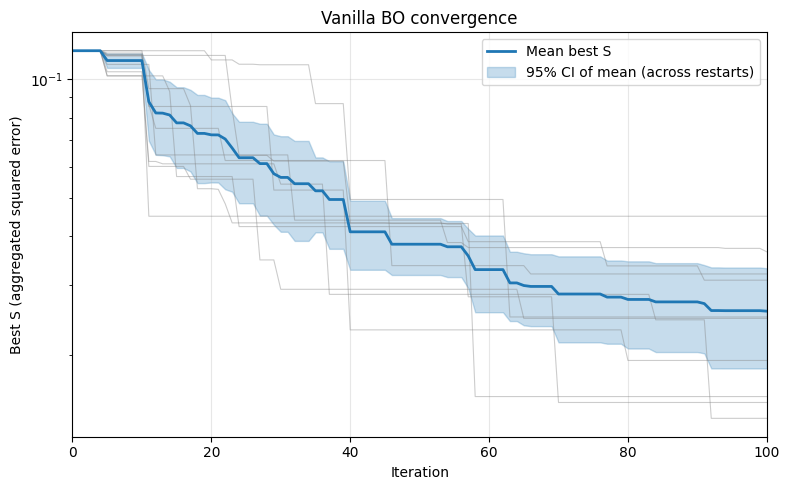

In [18]:
n_restarts = len(vanilla_histories_raw)
min_len = min(len(h) for h in vanilla_histories_raw)
aligned_histories = np.array([h[:min_len] for h in vanilla_histories_raw])

iters = np.arange(min_len)

# Mean and standard deviation across restarts
mean_curve = aligned_histories.mean(axis=0)

if n_restarts > 1:
    std_curve = aligned_histories.std(axis=0, ddof=1) 
else:
    std_curve = np.zeros_like(mean_curve)


if n_restarts > 1:
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1)
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts))
else:
    ci_half = np.zeros_like(mean_curve)




fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Individual restart curves
for h in vanilla_histories_raw:
    ax.plot(
        np.arange(min(len(h), min_len)),
        h[:min_len],
        color="gray",
        alpha=0.4,
        linewidth=0.8,
    )

# Mean curve
ax.plot(
    iters,
    mean_curve,
    color="C0",
    linewidth=2,
    label="Mean best S",
)

# 95% CI of the mean
ax.fill_between(
    iters,
    mean_curve - ci_half,
    mean_curve + ci_half,
    color="C0",
    alpha=0.25,
    label="95% CI of mean (across restarts)",
)


ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title("Vanilla BO convergence")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [19]:
import numpy as np
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "vanilla_bo" / "results"
df = pd.read_csv(results_dir / "all_restarts_convergence.csv")

restart_cols = [c for c in df.columns if c.startswith("restart_")]
padded = df[restart_cols].values

# Final Best S per restart
final_S = padded[-1, :]
order = np.argsort(final_S)
print("Restarts ranked by final Best S (lowest first):")
for j in order[:23]:
    print(f"  {restart_cols[j]}: final S = {final_S[j]:.2e}")

Restarts ranked by final Best S (lowest first):
  restart_7: final S = 1.38e-02
  restart_3: final S = 1.51e-02
  restart_8: final S = 1.57e-02
  restart_6: final S = 1.94e-02
  restart_4: final S = 2.48e-02
  restart_5: final S = 2.50e-02
  restart_2: final S = 3.09e-02
  restart_10: final S = 3.21e-02
  restart_9: final S = 3.65e-02
  restart_1: final S = 4.50e-02


# ind gp squared metric 

one gp per edge, is fitted on error

# initial data 

In [20]:
csv_path = Path(f"{config['simulation_run_path']}/initial_search/data_set_ods_20init.csv")

if csv_path.exists():
    print(f"✓ Loading initial data from {csv_path}")
    df_initial_bo = pd.read_csv(csv_path)

    x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
    x_cols.sort(key=lambda x: int(x.split("_")[1]))
    e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

    train_X_list = []
    train_E_list = []
    S_list = []

    for _, row in df_initial_bo.iterrows():
        train_X_list.append(row[x_cols].values.astype(float))
        train_E_list.append(row[e_cols].values.astype(float))
        S_list.append(float(row["loss"]))

    print(f"  Loaded {len(train_X_list)} initial points")
    print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")

else:
    train_X_list = []
    train_E_list = []
    S_list = []

    batch_data_i = []
    N_REP = 1

    for i, x in enumerate(train_X0.tolist()): 
        print(f"Initial OD: {i}")
        curr_od = np.array(x, dtype=float)
        print(curr_od)
        print(f"total expected demand: {np.sum(curr_od)}")

        simulation_run_path_init = f"{config['simulation_run_path']}/initial_search"
        Path(simulation_run_path_init).mkdir(parents=True, exist_ok=True)

        new_od_xml = f"{simulation_run_path_init}/gt_od_{config['network_name']}_{i}.xml"
        prefix_output_base = f"{simulation_run_path_init}/sobol_{i}"

        base_od = gt_od_df.copy()
        base_od["count"] = curr_od
        base_od["count"] = [round(v, 1) for v in base_od["count"]]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

        per_edge_errors_reps = []

        for rep in range(N_REP):
            print(f" Replication {rep}")
            prefix_output_rep = f"{prefix_output_base}_rep{rep}"

            simulate_od(
                new_od_xml,
                prefix_output_rep,
                base_path,
                config["net_xml"],
                config["taz2edge_xml"],
                config["additional_xml"],
                routes_df,
                config["sim_end_time"],
                config["TRIPS2ODS_OUT_STR"],
                sim_start_time=0,
                seed=rep,
            )

            sim_edge_out_rep = f"{prefix_output_rep}_{config['EDGE_OUT_STR']}"
            curr_loop_stats_rep, _, _ = parse_loop_data_xml_to_pandas(
                base_path,
                sim_edge_out_rep,
                prefix_output_rep,
                config["SUMO_PATH"],
            )

            sim_counts = (
                curr_loop_stats_rep[curr_loop_stats_rep["edge_id"].isin(edge_ids)]
                .set_index("edge_id")["interval_nVehContrib"]
                .loc[edge_ids]
                .values
            )

            print(f"\n--- Simulated flows for replication {rep} ---")
            for edge_id, count in zip(edge_ids, sim_counts):
                print(f"  {edge_id}: {count}")

            per_edge_errors_rep = compute_squared_metric_per_edge(
                df_true=gt_edge_data,
                df_simulated=curr_loop_stats_rep,
                edge_ids=edge_ids,
            )

            per_edge_errors_reps.append(per_edge_errors_rep)

        per_edge_errors_reps = np.stack(per_edge_errors_reps, axis=0)
        per_edge_errors = per_edge_errors_reps.mean(axis=0)

        S_x = float((per_edge_errors * weights_np).sum())
        print(f"aggregated loss S(x): {S_x}")

        train_X_list.append(curr_od.copy())
        train_E_list.append(per_edge_errors.copy())
        S_list.append(S_x)

        df_curr = pd.DataFrame(
            curr_od.reshape(1, -1),
            columns=[f"x_{k+1}" for k in range(curr_od.shape[0])]
        )
        df_curr["loss"] = S_x

        for edge_idx, edge_id in enumerate(edge_ids):
            df_curr[f"e_{edge_id}"] = per_edge_errors[edge_idx]

        batch_data_i.append(df_curr)

    if batch_data_i:
        df_initial_bo = pd.concat(batch_data_i, ignore_index=True)
        df_initial_bo.to_csv(csv_path, index=False)
        print(f"✓ Saved initial data to {csv_path}")

✓ Loading initial data from output/network_2corridor_bo_vanilla_matern-2p5/initial_search/data_set_ods_20init.csv
  Loaded 20 initial points
  OD dimension: 21, Edges: 51


In [ ]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import torch
import json

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

from src.utils.seed import set_seed
from src.models.gp_models import (
    initialize_independent_gp_models_with_modellist,
    make_linear_aggregation_model_from_error_gps,
    extract_independent_gp_hyperparameters,
)

dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Bounds for od
od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)

N_RESTARTS = 1  # config.get("NUM_RESTARTS", 10)
N_BO_ITERS = 100  # config.get("NITER", 100)
kernel = "matern-2p5"  # config.get("kernel", "matern-2p5")
BO_FOLDER = "indgp_bo_squared"

save_base = Path(config["simulation_run_path"]) / BO_FOLDER
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results"
results_dir.mkdir(parents=True, exist_ok=True)
initial_design_path = results_dir / "initial_design_squared.npz"

if initial_design_path.exists():
    data = np.load(initial_design_path)
    train_X_ind_init = torch.tensor(data["train_X"], dtype=dtype, device=device)
    train_Y_ind_init = torch.tensor(data["train_Y"], dtype=dtype, device=device)
    print(f"[INIT] Loaded initial design from {initial_design_path} (N={train_X_ind_init.shape[0]}, d={train_X_ind_init.shape[1]})")
else:
    train_X_ind_init = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)
    train_Y_ind_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)
    np.savez(
        initial_design_path,
        train_X=train_X_ind_init.cpu().numpy(),
        train_Y=train_Y_ind_init.cpu().numpy(),
    )
    print(f"[INIT] Saved initial design to {initial_design_path} (N={train_X_ind_init.shape[0]}, d={train_X_ind_init.shape[1]})")

N, d = train_X_ind_init.shape
L = train_Y_ind_init.shape[1]
assert len(edge_ids) == L, f"edge_ids ({len(edge_ids)}) must match L ({L})"

weights_t = torch.tensor(weights_np, dtype=dtype, device=device)

bounds = torch.stack([ # bounds for od vector 
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([ # bounds for normalized od vector used in EI
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)
skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)

indgp_histories_raw = []

for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"

    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        indgp_histories_raw.append(S_history)
        print(f"\n######### IND-GP BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(restart_seed)
    print(f"\n######### IND-GP BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")

    train_X_ind = train_X_ind_init.clone()
    train_Y_ind = train_Y_ind_init.clone()

    S_init = (train_Y_ind * weights_t).sum(dim=1)
    best_S_raw = S_init.min().item()
    S_history_raw = [best_S_raw]

    print(f"[INIT] N={train_X_ind.shape[0]}, best S (raw) = {best_S_raw:.6f}")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    no_improve_steps = 0
    best_checkpoint = best_S_raw

    for it in range(N_BO_ITERS):
        train_X_norm = normalize(train_X_ind, bounds=bounds)
        model_list_gp_errors, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_ind, kernel=kernel
        )
        for i, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except Exception as e:
                print(f"[WARNING] Edge {edge_ids[i]} fit warning: {str(e)[:80]}")

        agg_model = make_linear_aggregation_model_from_error_gps(
            model_list_gp_errors, weights=weights_t
        )
        agg_model.eval()

        EI = ExpectedImprovement(model=agg_model, best_f=best_S_raw, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acq_function=EI,
            bounds=bounds_norm,
            q=1,
            num_restarts=config.get("RAW_NUM_RESTARTS", 32),
            raw_samples=config.get("RAW_SAMPLES", 128),
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds=bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        sim_dir = save_base / f"restart_{r+1}_seed-{restart_seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        new_od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})

        create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)

        t0 = time.time()
        simulate_od(
            str(new_od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
        )
        print(f"[RUNTIME] Simulation took {time.time() - t0:.2f}s")

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )
        per_edge_errors = compute_squared_metric_per_edge(
            df_true=gt_edge_data,
            df_simulated=curr_loop_stats,
            edge_ids=edge_ids,
        )
        curr_loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(curr_loss):
            curr_loss = float("inf")

        if curr_loss < best_S_raw:
            best_S_raw = curr_loss
            print(f"[UPDATE] New BEST S = {best_S_raw:.6f}")
        else:
            print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")
        S_history_raw.append(best_S_raw)

        train_X_ind = torch.cat([
            train_X_ind,
            torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1),
        ], dim=0)
        train_Y_ind = torch.cat([
            train_Y_ind,
            torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1),
        ], dim=0)

        merged_data = pd.merge(
            gt_edge_data[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{curr_loss:.6f}.txt").write_text(f"LOSS: {curr_loss:.6f}")
        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")

        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={curr_loss:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

    indgp_histories_raw.append(S_history_raw)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")

    # Write convergence.csv right after this restart is done
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history_raw)), "best_S": S_history_raw}).to_csv(
        restart_dir / "convergence.csv", index=False
    )

    # Save last-iteration hyperparameters from last restart (for comparison with cubic)
    if r == N_RESTARTS - 1:
        train_X_norm = normalize(train_X_ind, bounds=bounds)
        model_list_gp_errors, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_ind, kernel=kernel
        )
        for i, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except Exception as e:
                print(f"[WARNING] Edge {edge_ids[i]} fit warning: {str(e)[:80]}")
        agg_model = make_linear_aggregation_model_from_error_gps(model_list_gp_errors, weights=weights_t)
        hp = extract_independent_gp_hyperparameters(agg_model, edge_ids=edge_ids)
        def _to_serializable(obj):
            if isinstance(obj, dict):
                return {k: _to_serializable(v) for k, v in obj.items()}
            if isinstance(obj, list):
                return [_to_serializable(x) for x in obj]
            if hasattr(obj, "item"):
                return float(obj)
            if isinstance(obj, (int, float, str, bool, type(None))):
                return obj
            return obj
        with open(results_dir / "hyperparameters_last_iteration.json", "w") as f:
            json.dump(_to_serializable(hp), f, indent=2)
        print(f"  ✓ Saved hyperparameters_last_iteration.json (last restart, last iteration)")
        if hp.get("per_edge"):
            pd.DataFrame(hp["per_edge"]).to_csv(results_dir / "hyperparameters_per_edge.csv", index=False)
            print(f"  ✓ Saved hyperparameters_per_edge.csv")

        # ----- Save cv_data.npz for cross_validate_indgp.py (with optional best-iteration plot data) -----
        S_all = (train_Y_ind * weights_t).sum(dim=1).cpu().numpy()
        best_idx = int(np.argmin(S_all))
        best_od = train_X_ind[best_idx].cpu().numpy()
        best_S = float(S_all[best_idx])
        print(f"  Best eval index: {best_idx}, S = {best_S:.6f}")
        gt_od_vals = gt_od_df["count"].astype(float).to_numpy()
        gt_flows = gt_edge_data.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
        sim_edge_counts_best = None
        try:
            sim_dir_best = restart_dir / "best_eval"
            sim_dir_best.mkdir(parents=True, exist_ok=True)
            new_od_xml = sim_dir_best / "od.xml"
            prefix_output = sim_dir_best / "sim"
            base_od = gt_od_df.copy()
            base_od["count"] = [round(v, 1) for v in best_od]
            base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
            create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)
            simulate_od(
                str(new_od_xml), str(prefix_output), base_path,
                config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
                routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            )
            sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
            curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
                base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
            )
            curr_loop_stats = curr_loop_stats[curr_loop_stats["edge_id"].isin(edge_ids)].set_index("edge_id")
            sim_edge_counts_best = curr_loop_stats.loc[edge_ids, "interval_nVehContrib"].values.astype(float)
            print("  ✓ Simulated best-iteration run for cv_data (edge scatter will be generated)")
        except Exception as e:
            print(f"  [Skip] Best-eval sim failed: {e}; cv_data saved without sim_edge_counts.")
        save_kw = dict(
            X=train_X_ind.cpu().numpy(),
            Y=train_Y_ind.cpu().numpy(),
            edge_ids=np.array(edge_ids),
            weights=weights_np,
            gt_od=gt_od_vals,
            gt_edge_counts=gt_flows,
        )
        if sim_edge_counts_best is not None:
            save_kw["sim_edge_counts"] = sim_edge_counts_best
        np.savez(restart_dir / "cv_data.npz", **save_kw)
        print("  ✓ Saved cv_data.npz for cross_validate_indgp.py")

# ----- Aggregate -----
max_len = max(len(h) for h in indgp_histories_raw)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(indgp_histories_raw):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in indgp_histories_raw]
overall_best = min(best_S_per_restart)

print("\n" + "=" * 60)
print("IND-GP BO COMPLETE")
print("=" * 60)
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

# ----- Save aggregated only (per-restart convergence.csv already written above) -----
pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X_ind_init.shape[0],
        "kernel": kernel,
        "metric": "squared_per_edge",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": indgp_histories_raw[r] + [np.nan] * (max_len - len(indgp_histories_raw[r]))
    for r in range(N_RESTARTS)
})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved: {results_dir}")
print(f"  - restart_X_seed-Y/convergence.csv (written after each restart)")
print(f"  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")

[INIT] Loaded initial design from output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/results/initial_design_squared.npz (N=20, d=21)

######### IND-GP BO RESTART 1/1 (seed=42) #########
[INIT] N=20, best S (raw) = 0.118207
Using provided weights (sum=1.000000, scale=51.000000, expect_flow_weights=False)
  Weight range: [0.019608, 0.019608]
  First 5 weights: [0.01960784 0.01960784 0.01960784 0.01960784 0.01960784]


/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_0/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/taz.xml --tazrelation-files output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_0/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_0/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_0/sim_trips.xml -b 0 -e 

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


Step #3900.00 (2ms ~= 500.00*RT, ~835500.00UPS, vehicles TOT 11369 ACT 1671 BUF 9171)     
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 3.63s
 Real time factor: 1074.97
 UPS: 1589848.401323
Vehicles:
 Inserted: 11369 (Loaded: 20540)
 Running: 1671
 Waiting: 9171
Statistics (avg of 9698):
 RouteLength: 3328.04
 Speed: 11.90
 Duration: 454.86
 WaitingTime: 1.98
 TimeLoss: 313.41
 DepartDelay: 170.54
DijkstraRouter answered 23833 queries and explored 22.58 edges on average.
DijkstraRouter spent 0.02s answering queries (0.00ms on average).
[RUNTIME] Simulation took 4.22s
[UPDATE] New BEST S = 0.095914
[BO iter 1/100] S(x_next)=0.095914, best S=0.095914, EI=0.219782
Using provided weights (sum=1.000000, scale=51.000000, expect_flow_weights=False)
  Weight range: [0.019608, 0.019608]
  First 5 weights: [0.01960784 0.01960784 0.01960784 0.01960784 0.01960784]


...

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


Step #3900.00 (1ms ~= 1000.00*RT, ~1255000.00UPS, vehicles TOT 11589 ACT 1255 BUF 6427)   
Simulation ended at time: 3900.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 2.89s
 Real time factor: 1350.42
 UPS: 1764379.847645
Vehicles:
 Inserted: 11589 (Loaded: 18016)
 Running: 1255
 Waiting: 6427
Statistics (avg of 10334):
 RouteLength: 3552.78
 Speed: 13.39
 Duration: 389.75
 WaitingTime: 1.83
 TimeLoss: 240.86
 DepartDelay: 137.46
DijkstraRouter answered 20228 queries and explored 24.38 edges on average.
DijkstraRouter spent 0.03s answering queries (0.00ms on average).
[RUNTIME] Simulation took 3.39s
[NO IMPROVEMENT] Best S remains 0.005005
[BO iter 84/100] S(x_next)=0.007177, best S=0.005005, EI=0.010116
Using provided weights (sum=1.000000, scale=51.000000, expect_flow_weights=False)
  Weight range: [0.019608, 0.019608]
  First 5 weights: [0.01960784 0.01960784 0.01960784 0.01960784 0.01960784]


/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_84/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/taz.xml --tazrelation-files output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_84/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_84/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_84/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/network_2corridor/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_squared/restart_1_seed-42/iter_84/sim_trips.xml -b 

pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db
pj_obj_create: Cannot find proj.db


# checking if all iteration start from same value

In [23]:
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "indgp_bo_squared" / "results"
N_RESTARTS = 20 

initial_best_S = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    conv_file = results_dir / f"restart_{r+1}_seed-{seed}" / "convergence.csv"
    if conv_file.exists():
        df = pd.read_csv(conv_file)
        s0 = df.loc[0, "best_S"]  # iteration 0
        initial_best_S.append((r + 1, seed, s0))


vals = [x[2] for x in initial_best_S]
print("Initial best_S (iteration 0) per restart:", initial_best_S)
print("All same?", len(set(vals)) == 1)
if len(set(vals)) == 1:
    print("Initial best_S =", vals[0])
else:
    print("Different values:", set(vals))

Initial best_S (iteration 0) per restart: []
All same? False
Different values: set()


In [29]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "indgp_bo_cubic" / "results"
# Pick the restart folder you want, e.g. first restart:
restart_name = "restart_1_seed-42"
conv_path = results_dir / restart_name / "convergence.csv"

if not conv_path.exists():
    print(f"File not found: {conv_path}")
else:
    df = pd.read_csv(conv_path)
    plt.figure(figsize=(8, 5))
    plt.plot(df["iteration"], df["best_S"], "o-", lw=2, markersize=4)
    plt.xlabel("Iteration")
    plt.ylabel("Best S")
    plt.title(f"IND-GP BO — {restart_name}")
    plt.yscale("log")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

File not found: output/network_2corridor_bo_vanilla_matern-2p5/indgp_bo_cubic/results/restart_1_seed-42/convergence.csv


In [24]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
import pandas as pd


BO_FOLDER = "indgp_bo_squared"
results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / "results"


indgp_histories_raw = []

for r in range(100):  # adjust if needed
    restart_seed = 42 + r * 1000
    conv_path = results_dir / f"restart_{r+1}_seed-{restart_seed}" / "convergence.csv"
    if not conv_path.exists():
        break
    df = pd.read_csv(conv_path)
    indgp_histories_raw.append(df["best_S"].values)

n_restarts = len(indgp_histories_raw)
assert n_restarts > 1, "Need at least 2 restarts for CI"

min_len = min(len(h) for h in indgp_histories_raw)
aligned = np.array([h[:min_len] for h in indgp_histories_raw])

iters = np.arange(min_len)


mean_curve = aligned.mean(axis=0)
std_curve = aligned.std(axis=0, ddof=1)

t_critical = stats.t.ppf(0.975, df=n_restarts - 1)
ci_half = t_critical * (std_curve / np.sqrt(n_restarts))


fig, ax = plt.subplots(1, 1, figsize=(8, 5))


for h in indgp_histories_raw:
    ax.plot(
        np.arange(min_len),
        h[:min_len],
        color="gray",
        alpha=0.4,
        linewidth=0.8,
    )

# Mean curve
ax.plot(
    iters,
    mean_curve,
    color="C0",
    linewidth=2,
    label="Mean best S",
)

# 95% CI of the mean
ax.fill_between(
    iters,
    mean_curve - ci_half,
    mean_curve + ci_half,
    color="C0",
    alpha=0.25,
    label="95% CI of mean (across restarts)",
)


ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title("IND-GP (squared) convergence")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()



AssertionError: Need at least 2 restarts for CI

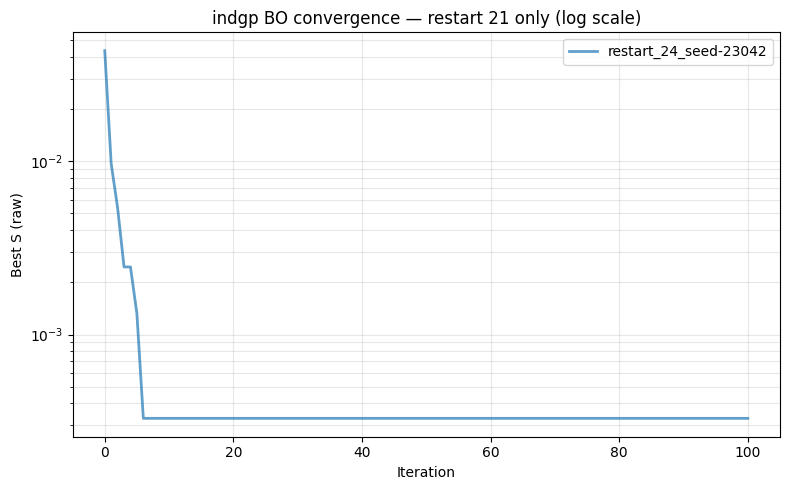

In [82]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
results_dir = Path(config["simulation_run_path"]) / "indgp_bo_squared" / "results"

restart_name = "restart_24_seed-23042" 
restart_dir = results_dir / restart_name

fig, ax = plt.subplots(figsize=(8, 5))
conv_path = restart_dir / "convergence.csv"
if conv_path.exists():
    df = pd.read_csv(conv_path)
    best_S = np.maximum(df["best_S"].values, 1e-10)
    ax.plot(df["iteration"], best_S, alpha=0.7, lw=2, label=restart_name)
else:
    print(f"Not found: {conv_path}")

ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (raw)")
ax.set_title("indgp BO convergence — restart 21 only (log scale)")
ax.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

# comparaison between sqaured error and cubic error for ind gp 

In [ ]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.quasirandom import SobolEngine
from botorch.utils.transforms import unnormalize

from src.simulation.sumo_runner import (
    create_od_xml,
    simulate_od,
    parse_loop_data_xml_to_pandas,
)

from src.optimization.bo_loop import BayesianOptimizationLoop
from src.optimization.restarts import run_multiple_bo_restarts

# ind gp with cubic error 

### using same initial points, but computing aggregated error

it doesnt make a diffeence as the way weaggrgate the eroor ( with the chosen wieght) the aggregated scalarzied value is equivalent 

In [40]:
#print(gt_edge_data.columns)
#print(gt_edge_data["interval_nVehContrib"])

In [41]:
csv_path = Path(f"{config['simulation_run_path']}/initial_search/data_set_ods_10init_cubic.csv")
#renamed for 10 initial points and cubic error

# Flow-proportional weights for cubic metric:
#   w_l = s_l^GT / (L * F_tot^GT)
# where F_tot^GT = sum_j s_j^GT (total GT flow over edges).
# Then sum_l w_l = 1/L (not 1).
gt_flows = gt_edge_data.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
L = len(edge_ids)
total_flow = gt_flows.sum()
weights_flow_np = gt_flows / (L * total_flow)




if csv_path.exists():
    print(f"Loading initial data from {csv_path}")
    df_initial_bo = pd.read_csv(csv_path)

    x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
    x_cols.sort(key=lambda x: int(x.split("_")[1]))
    e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

    train_X_list = []
    train_E_list = []
    S_list = []

    for _, row in df_initial_bo.iterrows():
        train_X_list.append(row[x_cols].values.astype(float))
        train_E_list.append(row[e_cols].values.astype(float))
        S_list.append(float(row["loss"]))

    print(f"  Loaded {len(train_X_list)} initial points")
    print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")

else:
    train_X_list = []     
    train_E_list = []    
    S_list       = []      

    batch_data_i = []    
    N_REP = 1

    for i, x in enumerate(train_X0.tolist()):
        print(f"Initial OD: {i}")
        curr_od = np.array(x, dtype=float)
        print(curr_od)
        print(f"total expected demand: {np.sum(curr_od)}")

        simulation_run_path_init = f"{config['simulation_run_path']}/initial_search/10init_cubic"
        Path(simulation_run_path_init).mkdir(parents=True, exist_ok=True)

        # OD xml for this candidate 
        new_od_xml = f"{simulation_run_path_init}/gt_od_{config['network_name']}_{i}.xml"
        prefix_output_base = f"{simulation_run_path_init}/sobol_{i}"

        base_od = gt_od_df.copy()
        base_od["count"] = curr_od
        base_od["count"] = [round(v, 1) for v in base_od["count"]]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

        per_edge_errors_reps = []

        for rep in range(N_REP):
            print(f"Replication {rep}")
            prefix_output_rep = f"{prefix_output_base}_rep{rep}"

            simulate_od(
                new_od_xml,
                prefix_output_rep,
                base_path,
                config["net_xml"],
                config["taz2edge_xml"],
                config["additional_xml"],
                routes_df,
                config["sim_end_time"],
                config["TRIPS2ODS_OUT_STR"],
                sim_start_time=0,
                seed=rep,   # different seed per replication
            )

            sim_edge_out_rep = f"{prefix_output_rep}_{config['EDGE_OUT_STR']}"
            curr_loop_stats_rep, _, _ = parse_loop_data_xml_to_pandas(
                base_path,
                sim_edge_out_rep,
                prefix_output_rep,
                config["SUMO_PATH"],
            )

            # simulated flows per edge
            sim_counts = (
                curr_loop_stats_rep[curr_loop_stats_rep["edge_id"].isin(edge_ids)]
                .set_index("edge_id")["interval_nVehContrib"]
                .loc[edge_ids]  # preserve order
                .values
            )

            print(f"\n Simulated flows for replication {rep}")
            for edge_id, count in zip(edge_ids, sim_counts):
                print(f"  {edge_id}: {count}")

            # per-edge error for this replication (e_l(x)), if we assume mutltiple replication keep compute_squared_metric_per_edge otherwise compute_nrmse_all_edges can be used
            # compute cubic error
            per_edge_errors_rep = compute_cubic_metric_per_edge(
                df_true=gt_edge_data,
                df_simulated=curr_loop_stats_rep,
                edge_ids=edge_ids,
            )  # np.array [L]

            per_edge_errors_reps.append(per_edge_errors_rep)

        per_edge_errors_reps = np.stack(per_edge_errors_reps, axis=0)  # [N_REP, L]
        per_edge_errors = per_edge_errors_reps.mean(axis=0)            # [L]

        # aggregated scalar loss S(x) = Σ_l w_l e_l(x) for the initial training  point
        S_x = float((per_edge_errors * weights_flow_np).sum())
        print(f"aggregated loss S(x): {S_x}")

        train_X_list.append(curr_od.copy())
        train_E_list.append(per_edge_errors.copy())
        S_list.append(S_x)

        df_curr = pd.DataFrame(
            curr_od.reshape(1, -1),
            columns=[f"x_{k+1}" for k in range(curr_od.shape[0])]
        )
        df_curr["loss"] = S_x

        # Add per-edge errors as columns (e_edge_id for each edge)
        for edge_idx, edge_id in enumerate(edge_ids):
            df_curr[f"e_{edge_id}"] = per_edge_errors[edge_idx]

        batch_data_i.append(df_curr)

    # Save initial dataset
    if batch_data_i:
        df_initial_bo = pd.concat(batch_data_i, ignore_index=True)
        df_initial_bo.to_csv(csv_path, index=False)
        print(f"✓ Saved initial data to {csv_path}")

Loading initial data from output/quickstart_bo_vanilla_matern-2p5/initial_search/data_set_ods_10init_cubic.csv
  Loaded 10 initial points
  OD dimension: 4, Edges: 14


In [42]:
#print(train_X_list)   
#print(train_E_list)    
print(S_list)  



[1.5431797909153078, 0.8662538000215959, 0.0661608171903682, 1.275962487744304, 0.5627743271424972, 0.1864039238383183, 0.0434194783500701, 2.0360066192635786, 0.8334976954612532, 0.5874082487492351]


In [43]:
print(weights_flow_np)

[0.00706436 0.00706436 0.00706436 0.00549451 0.00549451 0.00549451
 0.00549451 0.00549451 0.00549451 0.00392465 0.00392465 0.00392465
 0.00353218 0.00196232]


# match the squared error !!!! 

# then fit each gp on the eroor of the link then aggrzgate predicition so that the aggregated value are equivalen 

In [46]:
# loading dataset if not done yet


from src.utils.link_flow_analysis import compute_cubic_metric_per_edge

csv_path = Path(f"{config['simulation_run_path']}/initial_search/data_set_ods_10init_cubic.csv")
#renamed for 10 initial points and cubic error

# Flow-proportional weights for cubic metric:
#   w_l = s_l^GT / (L * F_tot^GT)
# where F_tot^GT = sum_j s_j^GT (total GT flow over edges).
# Then sum_l w_l = 1/L (not 1).
gt_flows = gt_edge_data.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
L = len(edge_ids)
total_flow = gt_flows.sum()
weights_flow_np = gt_flows / (L * total_flow)

if csv_path.exists():
    print(f"Loading initial data from {csv_path}")
    df_initial_bo = pd.read_csv(csv_path)

    x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
    x_cols.sort(key=lambda x: int(x.split("_")[1]))
    e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

    train_X_list = []
    train_E_list = []
    S_list = []

    for _, row in df_initial_bo.iterrows():
        train_X_list.append(row[x_cols].values.astype(float))
        train_E_list.append(row[e_cols].values.astype(float))
        S_list.append(float(row["loss"]))

    print(f"  Loaded {len(train_X_list)} initial points")
    print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")
else : 
    print('no data')

Loading initial data from output/quickstart_bo_vanilla_matern-2p5/initial_search/data_set_ods_10init_cubic.csv
  Loaded 10 initial points
  OD dimension: 4, Edges: 14


In [47]:
# IND-GP: fit GPs on CUBIC per-edge errors + flow-proportional aggregation

from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
import numpy as np
import torch
from botorch.utils.transforms import normalize

from src.models.gp_models import (
    initialize_independent_gp_models_with_modellist,
    make_linear_aggregation_model_from_error_gps,
)

dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# From your initial data (train_X_list, train_E_list from CSV or initial design)
train_X = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)
train_Y_errors = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)



# Flow-proportional weights: w_l = s_l^GT / (L * F_tot^GT)  →  sum = 1/L
gt_flows = gt_edge_data.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
L = len(edge_ids)
F_tot_GT = gt_flows.sum()
weights_flow_np = gt_flows / (L * F_tot_GT)
weights_flow_t = torch.tensor(weights_flow_np, dtype=dtype, device=device)

# bounds, bounds_norm, od_bound_start, od_bound_end, d — defined in Sobol/initial setup cell above

if hasattr(edge_ids, 'tolist'):
    edge_ids = edge_ids.tolist()

In [48]:

kernel = "matern-2p5"

# Normalize inputs to [0, 1] for GP
train_X_norm = normalize(train_X, bounds=bounds)

# independent GPs (one per edge), each fitted on cubic error for that edge
model_list_gp_errors, mlls = initialize_independent_gp_models_with_modellist(
    train_X_norm,
    train_Y_errors,
    kernel=kernel,
)

# Fiting each edge GP (maximize marginal log likelihood)
for i, mll in enumerate(mlls):
    try:
        fit_gpytorch_mll(mll)
    except Exception as e:
        print(f"  WARNING: Edge {edge_ids[i]} fit: {e}")

# Aggregation with flow-proportional weights -> S(x) = sum_l w_l * e_l^cb(x) = e_agg(x)
weights_flow_t = torch.tensor(weights_flow_t, dtype=dtype, device=device)
aggregated_gp_model = make_linear_aggregation_model_from_error_gps(
    model_list_gp_errors,
    weights=weights_flow_t,
    expect_flow_weights=True,
)
aggregated_gp_model.eval()

# Check initial aggregated loss
with torch.no_grad():
    post = aggregated_gp_model.posterior(train_X_norm)
    S_pred = post.mean.squeeze(-1)
print(f"IND-GP (cubic) fitted. Train S pred range: [{S_pred.min().item():.6f}, {S_pred.max().item():.6f}]")



# sum should be 1/L = 1/14 ≈ 0.07142857 ≈ 0.071429,


Using provided weights (sum=0.071429, scale=1.000000, expect_flow_weights=True)
  Weight range: [0.001962, 0.007064]
  First 5 weights: [0.00706436 0.00706436 0.00706436 0.00549451 0.00549451]
  Weights are flow-proportional (non-uniform)
IND-GP (cubic) fitted. Train S pred range: [0.043419, 2.036007]


/var/folders/ng/wz4hfzq14nggvhjg7kkdsts80000gn/T/ipykernel_36704/41639969.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights_flow_t = torch.tensor(weights_flow_t, dtype=dtype, device=device)


### full in gp cubic

In [ ]:
import time 

N_BO_ITERS = 100  # config.get("BO_niter", 100)
N_RESTARTS = 30  # config.get("NUM_RESTARTS", 10)
raw_samples = config.get("RAW_SAMPLES") or config.get("BO_raw_samples", 128)
kernel = config.get("kernel", "matern-2p5")
BO_FOLDER = "indgp_bo_cubic"
num_restarts = config.get("BO_num_restarts", 10)

od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)
d = train_X.shape[1]
bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])
assert train_X.min() >= od_bound_start and train_X.max() <= od_bound_end, (
    f"train_X should be in [{od_bound_start}, {od_bound_end}]; got min={train_X.min():.2f}, max={train_X.max():.2f}. "
    "Use same bounds in the initial-data (Sobol) cell."
)

use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)
skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)



# Path(config["simulation_run_path"])  = /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5
save_base = Path(config["simulation_run_path"]) / BO_FOLDER # output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic
# save_base = /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results" #/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/results
results_dir.mkdir(parents=True, exist_ok=True)

indgp_histories = []

for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{seed}"
    convergence_file = restart_dir / "convergence.csv"
    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        indgp_histories.append(S_history)
        print(f"\n######### IND-GP (cubic) RESTART {r+1}/{N_RESTARTS} (seed={seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(seed)
    print(f"\n######### IND-GP (cubic) RESTART {r+1}/{N_RESTARTS} (seed={seed}) #########")

    train_X_bo = train_X.clone()
    train_Y_errors_bo = train_Y_errors.clone()
    best_S_raw = float((train_Y_errors_bo * weights_flow_t).sum(dim=1).min())
    S_history = [best_S_raw]
    best_checkpoint = best_S_raw
    no_improve_steps = 0

    print(f"[BO INIT] N={train_X_bo.shape[0]}, best S (raw) = {best_S_raw:.6f}\n")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    for it in range(N_BO_ITERS):
        train_X_norm = normalize(train_X_bo, bounds=bounds)
        model_list_gp, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_errors_bo, kernel=kernel
        )
        for j, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except (NotPSDError, RuntimeError, ModelFittingError):
                print("[Fallback] Using Adam optimizer due to GP fitting failure.")
                optimizer = torch.optim.Adam([{"params": mll.parameters()}], lr=0.1)
                for _ in range(100):
                    optimizer.zero_grad()
                    output = mll.model(train_X_norm)
                    target = train_Y_errors_bo[:, j]  # j-th output for j-th GP
                    loss = -mll(output, target)
                    loss.backward()
                    optimizer.step()

        agg_model = make_linear_aggregation_model_from_error_gps( # for aggregation weights needs to be tensor
            model_list_gp, weights=weights_flow_t, expect_flow_weights=True
        )
        agg_model.eval()

        S_agg = (train_Y_errors_bo * weights_flow_t).sum(dim=1)
        best_f_for_ei = S_agg.min()

        acqf = ExpectedImprovement(model=agg_model, best_f=best_f_for_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acqf, bounds=bounds_norm, q=1, num_restarts=num_restarts, raw_samples=raw_samples
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        sim_dir = Path(config["simulation_run_path"]) / BO_FOLDER / f"restart_{r+1}_seed-{seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"
        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(od_xml), base_od, config["od_duration_sec"], base_path)
        simulate_od(
            str(od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
        )
        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"])
        )

        per_edge_cubic = compute_cubic_metric_per_edge(gt_edge_data, curr_loop_stats, edge_ids)
        S_next = float((np.array(per_edge_cubic) * weights_flow_np).sum())
        if np.any(np.isnan(per_edge_cubic)):
            S_next = float("inf")

        train_X_bo = torch.cat([train_X_bo, torch.tensor(x_next_real, dtype=dtype, device=device).unsqueeze(0)], dim=0)
        train_Y_errors_bo = torch.cat([
            train_Y_errors_bo,
            torch.tensor(per_edge_cubic, dtype=dtype, device=device).unsqueeze(0),
        ], dim=0)
        if S_next < best_S_raw:
            best_S_raw = S_next
        S_history.append(best_S_raw)

        merged_data = pd.merge(
            gt_edge_data[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{S_next:.6f}.txt").write_text(f"LOSS: {S_next:.6f}")
        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")

        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={S_next:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

    indgp_histories.append(S_history)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")

    #Write convergence.csv immediately after the restart is done 
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(
        restart_dir / "convergence.csv", index=False
    )

    # Save last-iteration hyperparameters from last restart (for comparison with squared)
    if r == N_RESTARTS - 1:
        train_X_norm = normalize(train_X_bo, bounds=bounds)
        model_list_gp, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_errors_bo, kernel=kernel
        )
        for i, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except Exception as e:
                print(f"[WARNING] Edge {edge_ids[i]} fit warning: {str(e)[:80]}")
        agg_model = make_linear_aggregation_model_from_error_gps(
            model_list_gp, weights=weights_flow_t, expect_flow_weights=True
        )
        hp = extract_independent_gp_hyperparameters(agg_model, edge_ids=edge_ids)
        def _to_serializable(obj):
            if isinstance(obj, dict):
                return {k: _to_serializable(v) for k, v in obj.items()}
            if isinstance(obj, list):
                return [_to_serializable(x) for x in obj]
            if hasattr(obj, "item"):
                return float(obj)
            if isinstance(obj, (int, float, str, bool, type(None))):
                return obj
            return obj
        with open(results_dir / "hyperparameters_last_iteration.json", "w") as f:
            json.dump(_to_serializable(hp), f, indent=2)
        print(f"  Saved hyperparameters_last_iteration.json (last restart, last iteration)")
        if hp.get("per_edge"):
            pd.DataFrame(hp["per_edge"]).to_csv(results_dir / "hyperparameters_per_edge.csv", index=False)
            print(f"  ✓ Saved hyperparameters_per_edge.csv")

        # Save cv_data.npz for cross_validate_indgp.py (with optional best-iteration plot data)
        S_all = (train_Y_errors_bo * weights_flow_t).sum(dim=1).cpu().numpy()
        best_idx = int(np.argmin(S_all))
        best_od = train_X_bo[best_idx].cpu().numpy()
        best_S = float(S_all[best_idx])
        print(f"  Best eval index: {best_idx}, S = {best_S:.6f}")
        gt_od_vals = gt_od_df["count"].astype(float).to_numpy()
        gt_flows = gt_edge_data.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
        sim_edge_counts_best = None
        try:
            sim_dir_best = restart_dir / "best_eval"
            sim_dir_best.mkdir(parents=True, exist_ok=True)
            new_od_xml = sim_dir_best / "od.xml"
            prefix_output = sim_dir_best / "sim"
            base_od = gt_od_df.copy()
            base_od["count"] = [round(v, 1) for v in best_od]
            base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
            create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)
            simulate_od(
                str(new_od_xml), str(prefix_output), base_path,
                config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
                routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            )
            sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
            curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
                base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
            )
            curr_loop_stats = curr_loop_stats[curr_loop_stats["edge_id"].isin(edge_ids)].set_index("edge_id")
            sim_edge_counts_best = curr_loop_stats.loc[edge_ids, "interval_nVehContrib"].values.astype(float)
            print("  Simulated best-iteration run for cv_data (edge scatter will be generated)")
        except Exception as e:
            print(f"  [Skip] Best-eval sim failed: {e}; cv_data saved without sim_edge_counts.")
        save_kw = dict(
            X=train_X_bo.cpu().numpy(),
            Y=train_Y_errors_bo.cpu().numpy(),
            edge_ids=np.array(edge_ids),
            weights=weights_flow_np,
            gt_od=gt_od_vals,
            gt_edge_counts=gt_flows,
        )
        if sim_edge_counts_best is not None:
            save_kw["sim_edge_counts"] = sim_edge_counts_best

        ##/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/results


        np.savez(restart_dir / "cv_data.npz", **save_kw) #         ##/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/results/"restart_23_seed-22042"/"cv_data.npz"
        print("  Saved cv_data.npz for cross_validate_indgp.py")

# Aggregate across restarts
max_len = max(len(h) for h in indgp_histories)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(indgp_histories):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in indgp_histories]
overall_best = min(best_S_per_restart)

print("\n" + "=" * 60)
print("IND-GP (cubic) BO COMPLETE")
print("=" * 60)
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

# Save aggregated results only (per-restart convergence.csv already written above) 
conv_df = pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
})
conv_df.to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X.shape[0],
        "kernel": kernel,
        "metric": "cubic",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({f"restart_{r+1}": indgp_histories[r] + [np.nan] * (max_len - len(indgp_histories[r])) for r in range(N_RESTARTS)})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")
print(f"\n✓ Saved: {results_dir}")
print(f"  - results/restart_X_seed-Y/convergence.csv (written after each restart)")
print(f"  - results/convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")


######### IND-GP (cubic) RESTART 1/24 (seed=42) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000057

######### IND-GP (cubic) RESTART 2/24 (seed=1042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000369

######### IND-GP (cubic) RESTART 3/24 (seed=2042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.001320

######### IND-GP (cubic) RESTART 4/24 (seed=3042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000115

######### IND-GP (cubic) RESTART 5/24 (seed=4042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000037

######### IND-GP (cubic) RESTART 6/24 (seed=5042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000018

######### IND-GP (cubic) RESTART 7/24 (seed=6042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000292

######### IND-GP (cubic) RESTART 8/24 (seed=7042) — SKIPPED (already saved) #########
  Loa

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_0/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_0/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_0/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_0/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesben

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_1/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_1/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_1/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_1/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_1/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesben

...

Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_97/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_97/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/qui

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)
/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/optim/optimize.py:362: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  generated_initial_conditions = opt_inputs.get_ic_generator()(


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_98/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_98/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/qui

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)
/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/optim/optimize.py:362: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  generated_initial_conditions = opt_inputs.get_ic_generator()(


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_99/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_cubic/restart_24_seed-23042/iter_99/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (1ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/qui

## convergence curve cubic 

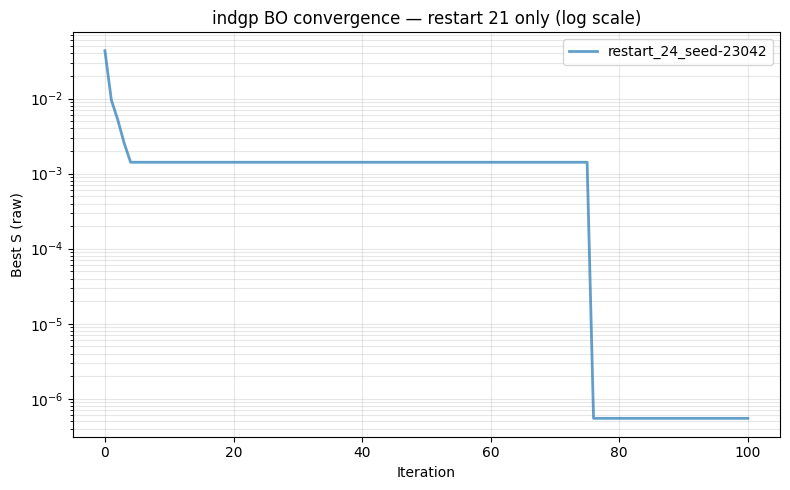

In [66]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
results_dir = Path(config["simulation_run_path"]) / "indgp_bo_cubic" / "results"

restart_name = "restart_24_seed-23042" 
restart_dir = results_dir / restart_name

fig, ax = plt.subplots(figsize=(8, 5))
conv_path = restart_dir / "convergence.csv"
if conv_path.exists():
    df = pd.read_csv(conv_path)
    best_S = np.maximum(df["best_S"].values, 1e-10)
    ax.plot(df["iteration"], best_S, alpha=0.7, lw=2, label=restart_name)
else:
    print(f"Not found: {conv_path}")

ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (raw)")
ax.set_title("indgp BO convergence — restart 21 only (log scale)")
ax.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

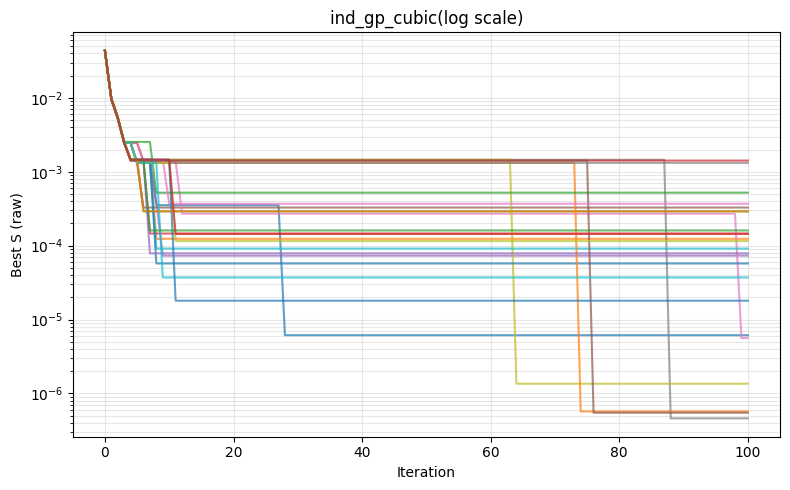

In [67]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
results_dir = Path(config["simulation_run_path"]) / "indgp_bo_cubic" / "results"

fig, ax = plt.subplots(figsize=(8, 5))
for restart_dir in sorted(results_dir.glob("restart_*_seed-*")):
    conv_path = restart_dir / "convergence.csv"
    if conv_path.exists():
        df = pd.read_csv(conv_path)
        best_S = np.maximum(df["best_S"].values, 1e-10)
        ax.plot(df["iteration"], best_S, alpha=0.7, lw=1.5, label=restart_dir.name)

ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (raw)")
ax.set_title("ind_gp_cubic(log scale)")
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

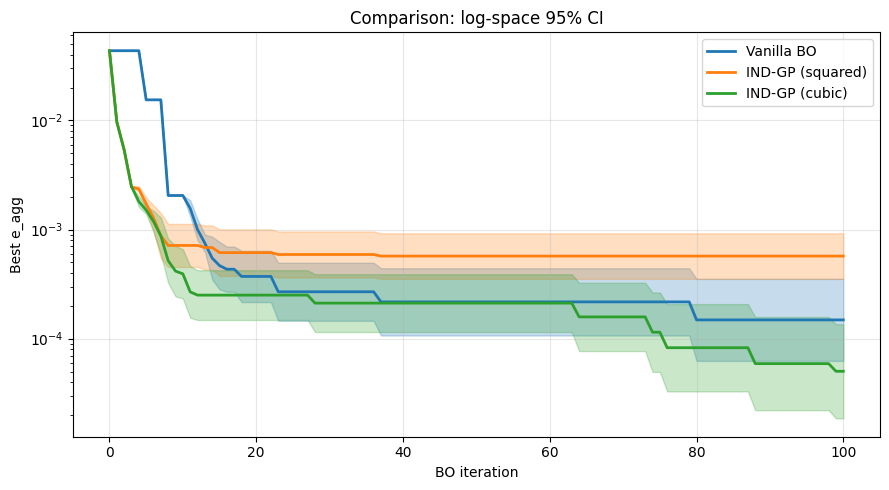

In [83]:
# geometric mean 

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base = Path(config["simulation_run_path"])
methods = {
    "Vanilla BO": base / "vanilla_bo" / "results" / "all_restarts_convergence.csv",
    "IND-GP (squared)": base / "indgp_bo_squared" / "results" / "all_restarts_convergence.csv",
    "IND-GP (cubic)": base / "indgp_bo_cubic" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
colors = {"Vanilla BO": "C0", "IND-GP (squared)": "C1", "IND-GP (cubic)": "C2"}

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path)
    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if not restart_cols:
        print(f"Skip {label}: no restart columns in {path}")
        continue

    padded = df[restart_cols].to_numpy(dtype=float)  # shape (T, R)

    logS = np.log10(padded)  # (T, R)

    mean_log = np.nanmean(logS, axis=1)
    std_log = np.nanstd(logS, axis=1)
    n_valid = np.sum(~np.isnan(logS), axis=1)

    tcrit = np.where(n_valid > 1, stats.t.ppf(0.975, n_valid - 1), np.nan)
    se_log = np.where(n_valid > 1, std_log / np.sqrt(n_valid), 0.0)
    ci_half_log = np.where(n_valid > 1, tcrit * se_log, 0.0)

    lower = 10 ** (mean_log - ci_half_log)
    upper = 10 ** (mean_log + ci_half_log)
    mean_s = 10 ** mean_log  
    iters = np.arange(len(mean_s))
    c = colors.get(label, "gray")

    ax.plot(iters, mean_s, color=c, linewidth=2, label=label)
    ax.fill_between(iters, lower, upper, alpha=0.25, color=c)

ax.set_xlabel("BO iteration")
ax.set_ylabel("Best e_agg")
ax.set_title("Comparison: log-space 95% CI")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_yscale("log")
plt.tight_layout()
plt.show()


In [69]:
import numpy as np
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "indgp_bo_cubic" / "results"
df = pd.read_csv(results_dir / "all_restarts_convergence.csv")

restart_cols = [c for c in df.columns if c.startswith("restart_")]
padded = df[restart_cols].values

# Final Best S per restart
final_S = padded[-1, :]
order = np.argsort(final_S)
print("Restarts ranked by final Best S (lowest first):")
for j in order[:23]:
    print(f"  {restart_cols[j]}: final S = {final_S[j]:.2e}")

Restarts ranked by final Best S (lowest first):
  restart_17: final S = 4.61e-07
  restart_24: final S = 5.49e-07
  restart_20: final S = 5.71e-07
  restart_18: final S = 1.36e-06
  restart_16: final S = 5.63e-06
  restart_10: final S = 6.15e-06
  restart_6: final S = 1.80e-05
  restart_5: final S = 3.72e-05
  restart_1: final S = 5.75e-05
  restart_14: final S = 7.33e-05
  restart_23: final S = 7.88e-05
  restart_19: final S = 9.14e-05
  restart_4: final S = 1.15e-04
  restart_11: final S = 1.24e-04
  restart_9: final S = 1.44e-04
  restart_13: final S = 1.46e-04
  restart_8: final S = 1.61e-04
  restart_7: final S = 2.92e-04
  restart_12: final S = 2.92e-04
  restart_15: final S = 3.28e-04
  restart_2: final S = 3.69e-04
  restart_21: final S = 5.22e-04
  restart_3: final S = 1.32e-03


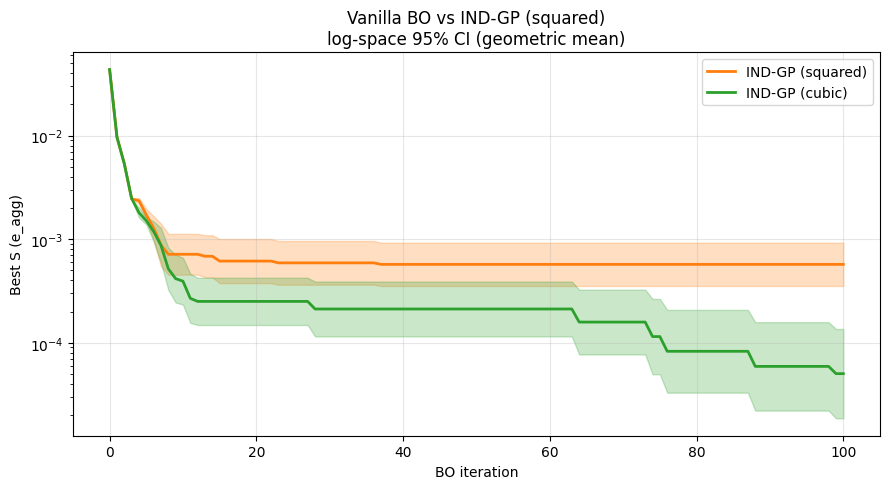

In [81]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base = Path(config["simulation_run_path"])

methods = {
    #"Vanilla BO": base / "vanilla_bo" / "results" / "all_restarts_convergence.csv",
    "IND-GP (squared)": base / "indgp_bo_squared" / "results" / "all_restarts_convergence.csv",
    "IND-GP (cubic)": base / "indgp_bo_cubic" / "results" / "all_restarts_convergence.csv",

}

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
colors = {"Vanilla BO": "C0", "IND-GP (squared)": "C1", "IND-GP (cubic)": "C2"}

EPS = 1e-30 

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path)
    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if not restart_cols:
        print(f"Skip {label}: no restart columns")
        continue

    padded = df[restart_cols].to_numpy(dtype=float) 
    padded = np.where(np.isfinite(padded), np.maximum(padded, EPS), np.nan)

    logS = np.log10(padded)

    mean_log = np.nanmean(logS, axis=1)
    std_log = np.nanstd(logS, axis=1)
    n_valid = np.sum(~np.isnan(logS), axis=1)

    tcrit = np.where(n_valid > 1, stats.t.ppf(0.975, n_valid - 1), 0.0)
    se_log = np.where(n_valid > 1, std_log / np.sqrt(n_valid), 0.0)
    ci_half_log = tcrit * se_log

    mean_s = 10 ** mean_log
    lower = 10 ** (mean_log - ci_half_log)
    upper = 10 ** (mean_log + ci_half_log)

    iters = np.arange(len(mean_s))
    c = colors[label]

    ax.plot(iters, mean_s, color=c, linewidth=2, label=label)
    ax.fill_between(iters, lower, upper, color=c, alpha=0.25)

ax.set_xlabel("BO iteration")
ax.set_ylabel("Best S (e_agg)")
ax.set_title("Vanilla BO vs IND-GP (squared)\nlog-space 95% CI (geometric mean)")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "indgp_bo_cubic" / "results"
N_RESTARTS = 20  

initial_best_S = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    conv_file = results_dir / f"restart_{r+1}_seed-{seed}" / "convergence.csv"
    if conv_file.exists():
        df = pd.read_csv(conv_file)
        s0 = df.loc[0, "best_S"]  # iteration 0
        initial_best_S.append((r + 1, seed, s0))

# All iteration-0 values should be the same
vals = [x[2] for x in initial_best_S]
print("Initial best_S (iteration 0) per restart:", initial_best_S)
print("All same?", len(set(vals)) == 1)
if len(set(vals)) == 1:
    print("Initial best_S =", vals[0])
else:
    print("Different values:", set(vals))

Initial best_S (iteration 0) per restart: [(1, 42, np.float64(0.0434629552964042)), (2, 1042, np.float64(0.0434629552964042)), (3, 2042, np.float64(0.0434629552964042)), (4, 3042, np.float64(0.0434629552964042)), (5, 4042, np.float64(0.0434629552964042)), (6, 5042, np.float64(0.0434629552964042)), (7, 6042, np.float64(0.0434629552964042)), (8, 7042, np.float64(0.0434629552964042)), (9, 8042, np.float64(0.0434629552964042)), (10, 9042, np.float64(0.0434629552964042)), (11, 10042, np.float64(0.0434629552964042)), (12, 11042, np.float64(0.0434629552964042)), (13, 12042, np.float64(0.0434629552964042)), (14, 13042, np.float64(0.0434629552964042)), (15, 14042, np.float64(0.0434629552964042)), (16, 15042, np.float64(0.0434629552964042)), (17, 16042, np.float64(0.0434629552964042)), (18, 17042, np.float64(0.0434629552964042)), (19, 18042, np.float64(0.0434629552964042)), (20, 19042, np.float64(0.0434629552964042))]
All same? True
Initial best_S = 0.0434629552964042


In [ ]:
results_dir = Path(config["simulation_run_path"]) / "vanilla_bo" / "results"
N_RESTARTS = 20  

initial_best_S = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    conv_file = results_dir / f"restart_{r+1}_seed-{seed}" / "convergence.csv"
    if conv_file.exists():
        df = pd.read_csv(conv_file)
        s0 = df.loc[0, "best_S"]  # iteration 0
        initial_best_S.append((r + 1, seed, s0))

# All iteration-0 values should be the same
vals = [x[2] for x in initial_best_S]
print("Initial best_S (iteration 0) per restart:", initial_best_S)
print("All same?", len(set(vals)) == 1)
if len(set(vals)) == 1:
    print("Initial best_S =", vals[0])
else:
    print("Different values:", set(vals))

Initial best_S (iteration 0) per restart: [(1, 42, np.float64(0.0434629552964042)), (2, 1042, np.float64(0.0434629552964042)), (3, 2042, np.float64(0.0434629552964042)), (4, 3042, np.float64(0.0434629552964042)), (5, 4042, np.float64(0.0434629552964042)), (6, 5042, np.float64(0.0434629552964042)), (7, 6042, np.float64(0.0434629552964042)), (8, 7042, np.float64(0.0434629552964042)), (9, 8042, np.float64(0.0434629552964042)), (10, 9042, np.float64(0.0434629552964042)), (11, 10042, np.float64(0.0434629552964042)), (12, 11042, np.float64(0.0434629552964042)), (13, 12042, np.float64(0.0434629552964042)), (14, 13042, np.float64(0.0434629552964042)), (15, 14042, np.float64(0.0434629552964042)), (16, 15042, np.float64(0.0434629552964042)), (17, 16042, np.float64(0.0434629552964042)), (18, 17042, np.float64(0.0434629552964042)), (19, 18042, np.float64(0.0434629552964042)), (20, 19042, np.float64(0.0434629552964042))]
All same? True
Initial best_S = 0.0434629552964042


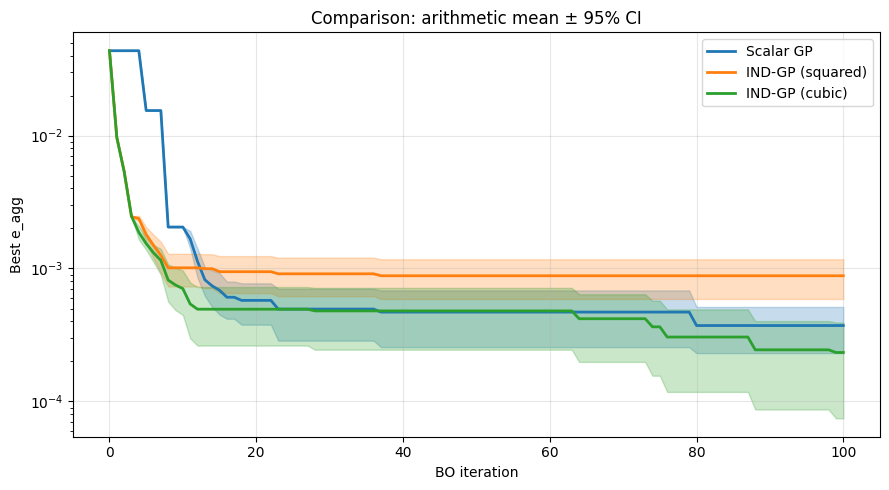

In [80]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

base = Path(config["simulation_run_path"])
methods = {
    "Scalar GP": base / "vanilla_bo" / "results" / "all_restarts_convergence.csv",
    "IND-GP (squared)": base / "indgp_bo_squared" / "results" / "all_restarts_convergence.csv",
    "IND-GP (cubic)": base / "indgp_bo_cubic" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
colors = {"Scalar GP": "C0", "IND-GP (squared)": "C1", "IND-GP (cubic)": "C2"}

EPS = 1e-30

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path)
    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if not restart_cols:
        print(f"Skip {label}: no restart columns in {path}")
        continue

    curves = df[restart_cols].to_numpy(dtype=float)
    curves = np.where(np.isfinite(curves), np.maximum(curves, EPS), np.nan)

    mean_s = np.nanmean(curves, axis=1)
    std_s = np.nanstd(curves, axis=1, ddof=1)
    n_valid = np.sum(~np.isnan(curves), axis=1)

    tcrit = np.where(n_valid > 1, stats.t.ppf(0.975, n_valid - 1), np.nan)
    se = np.where(n_valid > 1, std_s / np.sqrt(n_valid), 0.0)
    ci_half = np.where(n_valid > 1, tcrit * se, 0.0)
    lower = np.maximum(mean_s - ci_half, EPS)
    upper = mean_s + ci_half

    iters = np.arange(len(mean_s))
    c = colors.get(label, "gray")

    ax.plot(iters, mean_s, color=c, linewidth=2, label=label)
    ax.fill_between(iters, lower, upper, alpha=0.25, color=c)

ax.set_xlabel("BO iteration")
ax.set_ylabel("Best e_agg")
ax.set_title("Comparison: arithmetic mean ± 95% CI")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_yscale("log")
plt.tight_layout()
plt.show()